Блок 1: Импорт модулей, создание автономной модели d16_qwen_model2 и стартовый снимок всех весов D16Parameter

In [1]:
import importlib
from pathlib import Path
import sys
import torch

# 1. Подключаем папку с исходниками
for candidate in (Path.cwd() / "src", Path.cwd().parent / "src", Path.cwd()):
    if (candidate / "d16_qwen_model2.py").is_file() and str(candidate) not in sys.path:
        sys.path.insert(0, str(candidate))
        break

import d16_complex
import d16_parameter
import d16_adamw
import d16_qwen_model2
import d16_vis_utils

importlib.reload(d16_complex)
importlib.reload(d16_parameter)
importlib.reload(d16_adamw)
importlib.reload(d16_qwen_model2)
importlib.reload(d16_vis_utils)

from d16_adamw import D16AdamW
from d16_complex import D16ComplexTensor
from d16_qwen_model2 import D16QwenConfig, D16QwenForCausalLM, encode_token_ids
from d16_vis_utils import (
    D16TrajectoryRecorder,
    print_d16_weight_migration_table,
    snapshot_d16_weight_states,
)

# 2. Тестовые последовательности токенов, закодированные в D16
raw_tokens = torch.tensor(
    [
        [1, 5, 9, 13, 17, 21, 25, 29, 2, 6, 10, 14],
        [3, 7, 11, 15, 19, 23, 27, 31, 4, 8, 12, 16],
    ],
    dtype=torch.long,
)
d16_tokens = encode_token_ids(raw_tokens)

# 3. Конфигурация полностью автономной модели d16_qwen_model2
torch.manual_seed(42)
cfg = D16QwenConfig(
    vocab_size=32,
    hidden_size=32,          # 16 комплексных каналов D16
    intermediate_size=48,    # 48 комплексных нейронов в MLP
    num_hidden_layers=2,
    num_attention_heads=4,
    num_key_value_heads=2,
    indiff_eps="auto",
    indiff_rel=0.30,
    mlp_activation="bilinear",
    collect_d16_stats=True,
)
model = D16QwenForCausalLM(cfg)

# 4. Снимок начального состояния весов до обучения (включая 1D gain в D16RMSNorm)
init_snapshot = snapshot_d16_weight_states(model, include_biases=True)
_ = print_d16_weight_migration_table(model, include_biases=True)

КАРТА КОМПЛЕКСНЫХ ВЕСОВ D16Parameter (ТРОЙКИ x, y, rotation В КЛИНЕ [0°, 22.5°])
Модуль D16Parameter                    | Форма        | Средн. |z| | Клин y/x |  0xFFFF | Сменили сектор      
--------------------------------------------------------------------------------------------------------------------
model.embed_tokens.weight              | (32, 16)     |     0.0261 |   0.1982 |   0.00% | n/a (нет снимка)    
model.layers.0.input_layernorm.gain    | (16,)        |     1.0000 |   0.0000 |   0.00% | n/a (нет снимка)    
model.layers.0.self_attn.q_proj.weight | (16, 16)     |     0.1383 |   0.1940 |   0.00% | n/a (нет снимка)    
model.layers.0.self_attn.q_proj.bias   | (16,)        |     0.0000 |   0.0000 | 100.00% | n/a (нет снимка)    
model.layers.0.self_attn.k_proj.weight | (8, 16)      |     0.1314 |   0.2112 |   0.00% | n/a (нет снимка)    
model.layers.0.self_attn.k_proj.bias   | (8,)         |     0.0000 |   0.0000 | 100.00% | n/a (нет снимка)    
model.layers.0.self_attn.

Блок 2: Обучение через D16AdamW, запись траекторий секторов и итоговая таблица миграции весов

In [2]:
import math
from d16_vis_utils import print_d16_trajectory_summary

# 1. Инициализируем оптимизатор D16AdamW и рекордер траекторий
optimizer = D16AdamW(
    model.d16_parameters(),
    lr=2.5e-2,
    weight_decay=1e-3,
    indiff_eps="auto",
    indiff_rel=0.35,
)
recorder = D16TrajectoryRecorder(model, tracked_synapses_per_group=4)

# Снимаем стартовый Loss на шаге 0 до первого шага оптимизатора
model.train()
with torch.no_grad():
    out0 = model(input_ids=d16_tokens, labels=d16_tokens)
    recorder.record_step(0, model, loss=float(out0.loss.x.item()))

# 2. Цикл обучения (30 шагов)
print(f"{'Шаг':>4} | {'Loss':>8} | {'PPL':>6} | {'Норма град.':>11} | {'Акт. 0xFFFF':>11}")
print("-" * 52)

for step in range(1, 31):
    optimizer.zero_grad()
    model.set_collect_d16_stats(True, reset=True)
    out = model(input_ids=d16_tokens, labels=d16_tokens)
    loss_val = float(out.loss.x.item())
    out.loss.x.backward()
    grad_norm = float(optimizer.step(max_grad_norm=1.0).item())
    recorder.record_step(step, model, loss=loss_val)

    if step == 1 or step % 5 == 0:
        act_sp = model.get_d16_state_summary()["indifferent_pct"]
        ppl = math.exp(min(loss_val, 20.0))
        print(f"{step:4d} | {loss_val:8.4f} | {ppl:6.2f} | {grad_norm:11.4f} | {act_sp:10.2f}%")

# 3. Проверка авторегрессионной генерации с KV-кэшем
model.eval()
with torch.no_grad():
    generated = model.generate(d16_tokens[:, :4], max_new_tokens=8, do_sample=False, use_cache=True)
    gen_ids = generated.x.to(torch.long)
    exact_match = bool((gen_ids == raw_tokens).all().item())
    print("\nТочное совпадение сгенерированных последовательностей:", exact_match)
    print("Ожидалось :", raw_tokens.tolist())
    print("Получено  :", gen_ids.tolist())

# 4. Сводка динамики секторов по шагам и итоговая таблица миграции весов
print()
print_d16_trajectory_summary(recorder, every_n=5)
print()
final_summary = print_d16_weight_migration_table(
    model, initial_snapshot=init_snapshot, include_biases=True
)

 Шаг |     Loss |    PPL | Норма град. | Акт. 0xFFFF
----------------------------------------------------
   1 |   3.4620 |  31.88 |      1.3543 |       5.69%
   5 |   3.0341 |  20.78 |      1.5404 |       5.95%
  10 |   2.0215 |   7.55 |      1.0386 |       5.25%
  15 |   1.1036 |   3.02 |      0.9419 |       5.73%
  20 |   0.4218 |   1.52 |      0.5543 |       5.34%
  25 |   0.1126 |   1.12 |      0.2047 |       5.51%
  30 |   0.0507 |   1.05 |      0.5786 |       5.73%

Точное совпадение сгенерированных последовательностей: True
Ожидалось : [[1, 5, 9, 13, 17, 21, 25, 29, 2, 6, 10, 14], [3, 7, 11, 15, 19, 23, 27, 31, 4, 8, 12, 16]]
Получено  : [[1, 5, 9, 13, 17, 21, 25, 29, 2, 6, 10, 14], [3, 7, 11, 15, 19, 23, 27, 31, 4, 8, 12, 16]]

ДИНАМИКА СЕКТОРОВ ВЕСОВ D16Parameter ПО ШАГАМ ОБУЧЕНИЯ: ATTENTION vs MLP vs EMBEDDING
 Шаг |    Loss | Attn Cumul% | MLP Cumul% | Emb Cumul% | Attn Flip/шаг | MLP Flip/шаг | Attn 45°% | MLP 45°%
----------------------------------------------------------

Блок 3: Визуализация секторов, клина $[0^\circ, 22.5^\circ]$, траекторий обучения и тепловой карты внимания wedge_softmax

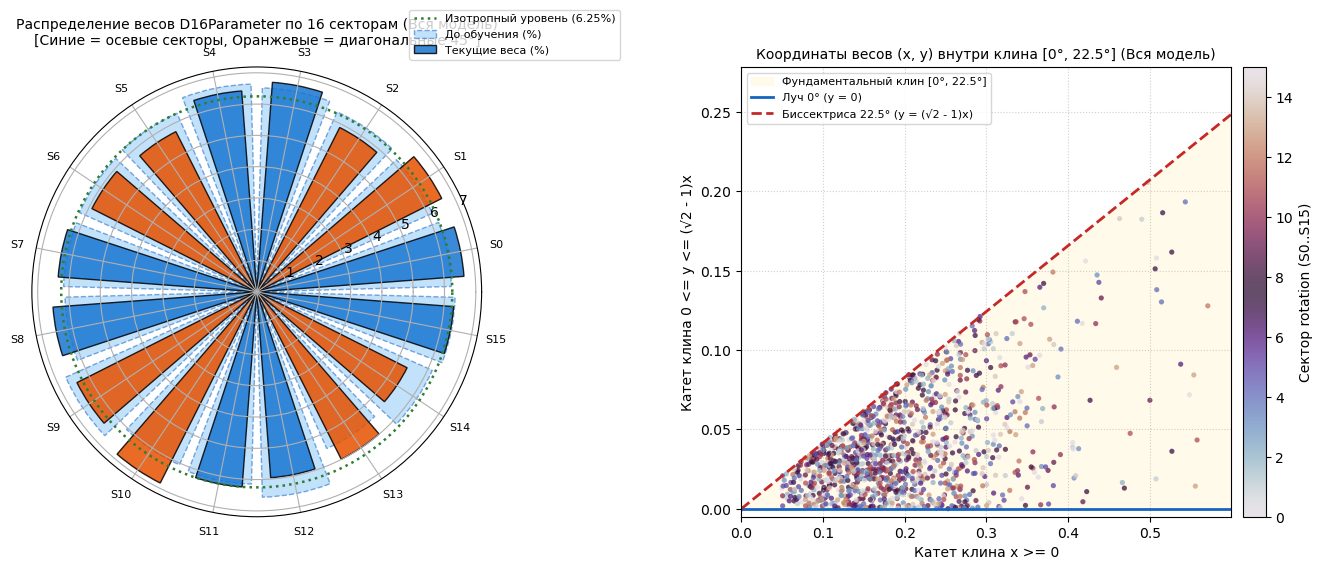

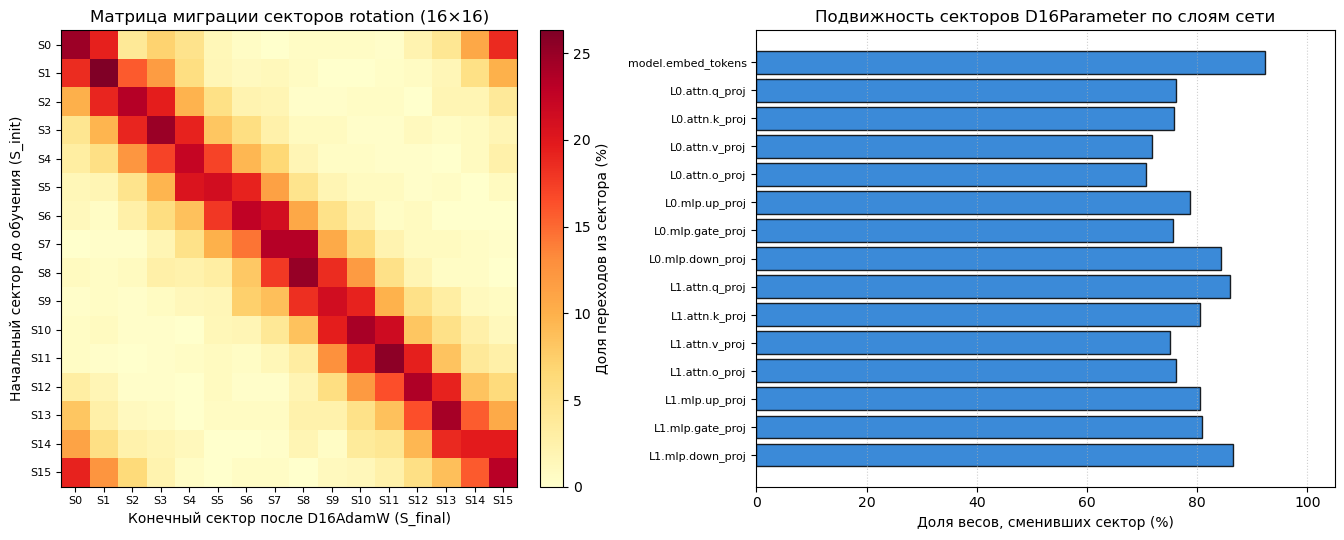

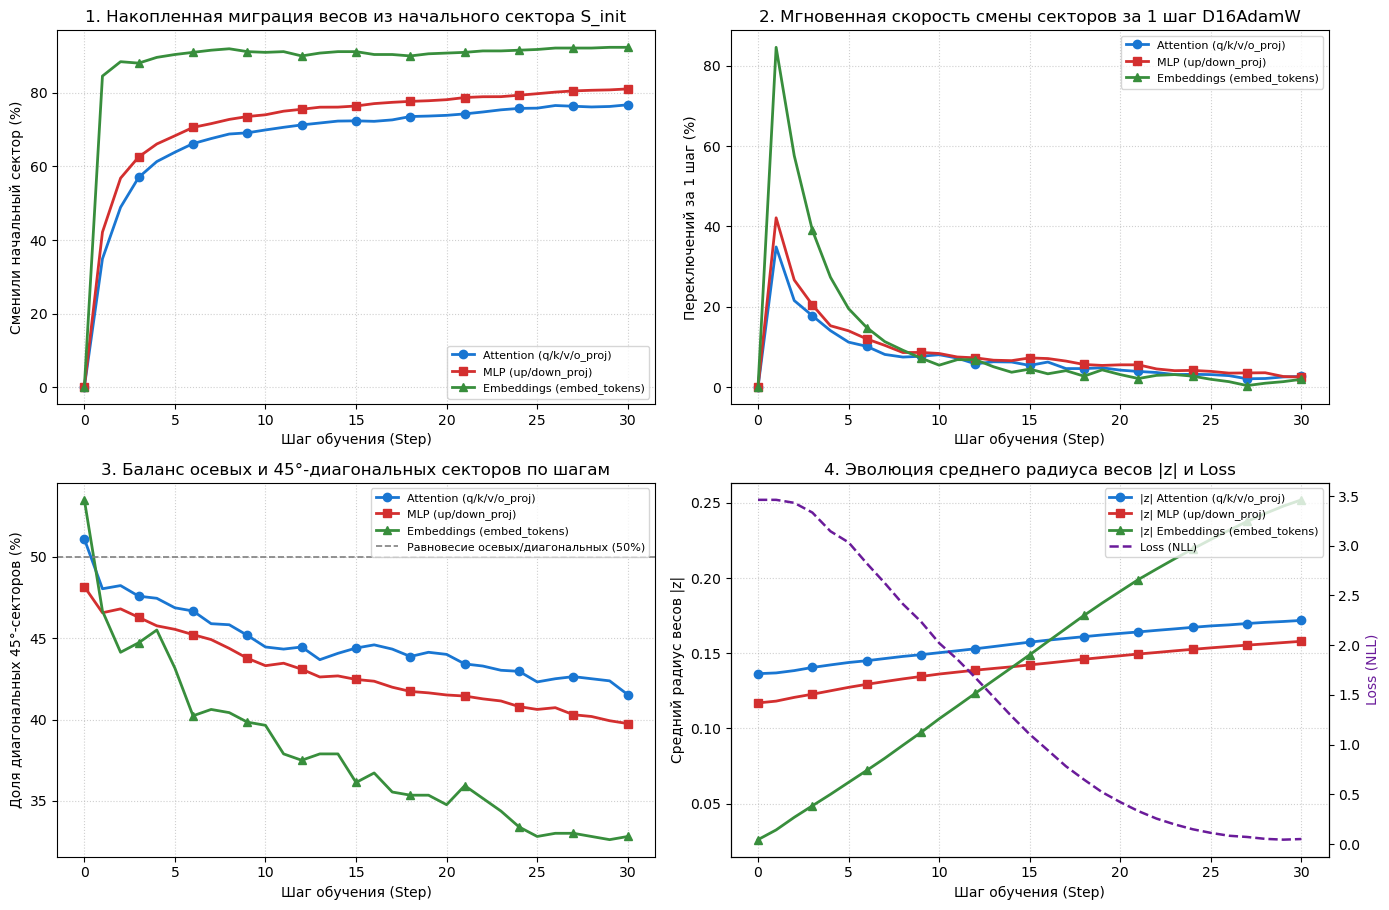

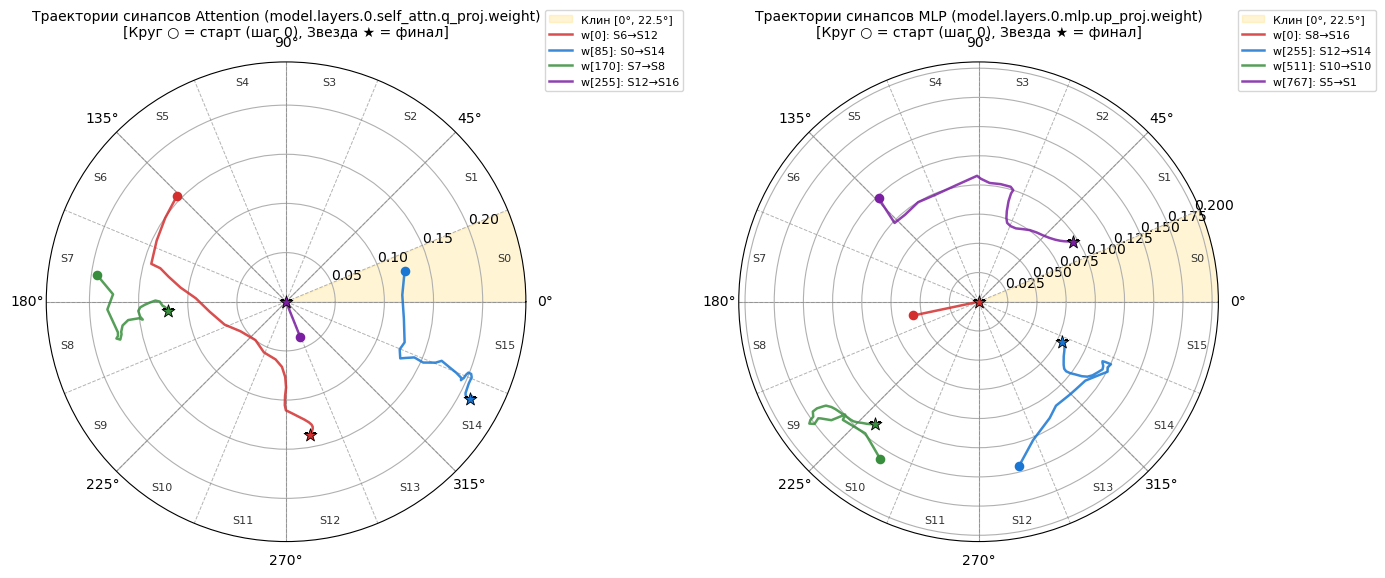

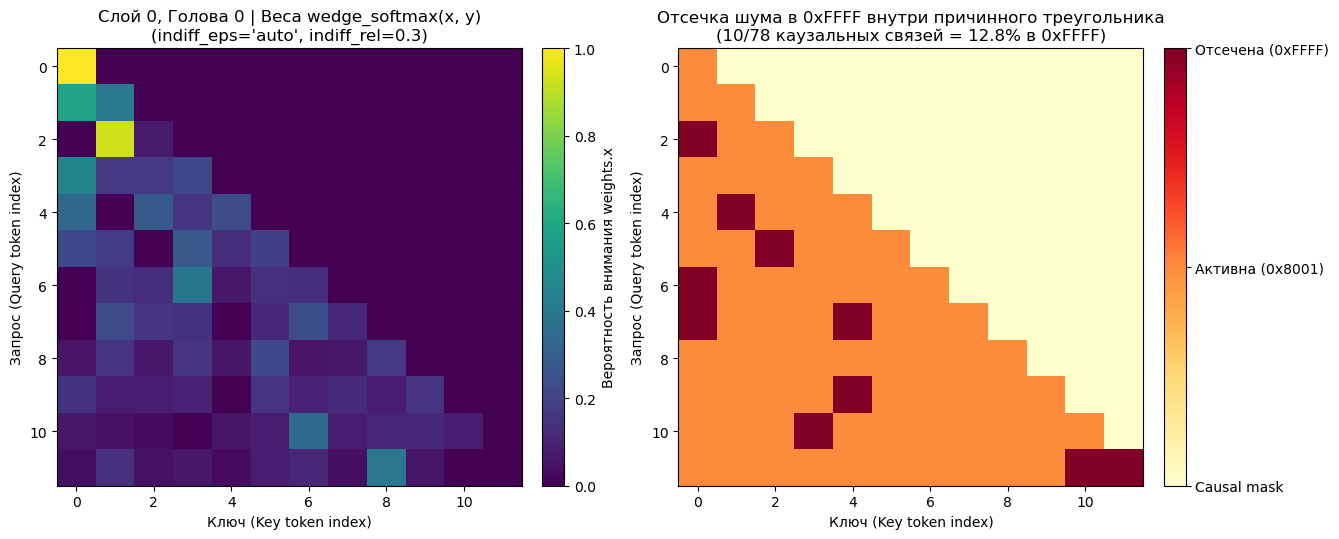

In [3]:
import matplotlib.pyplot as plt
from d16_vis_utils import (
    plot_d16_attention_heatmap,
    plot_d16_sector_trajectories,
    plot_d16_sector_transition_matrix,
    plot_d16_synapse_polar_trajectories,
    plot_d16_weight_sector_distribution,
)

# 1. Распределение весов по 16 секторам и внутри клина [0°, 22.5°]
fig1 = plot_d16_weight_sector_distribution(model, initial_snapshot=init_snapshot)
plt.show()

# 2. Матрица миграции секторов (16x16) и подвижность по слоям
fig2 = plot_d16_sector_transition_matrix(model, initial_snapshot=init_snapshot)
plt.show()

# 3. Пошаговая динамика обучения: Attention vs MLP vs Embedding
fig3 = plot_d16_sector_trajectories(recorder)
plt.show()

# 4. Полярные траектории отдельных синапсов Attention и MLP
fig4 = plot_d16_synapse_polar_trajectories(recorder)
plt.show()

# 5. Тепловая карта вероятностей внимания wedge_softmax(x, y) и отсечки 0xFFFF
fig5 = plot_d16_attention_heatmap(model, d16_tokens, layer_idx=0, head_idx=0)
plt.show()

Блок 4: Прямое сравнение всех режимов активации D16QwenMLP ("bilinear", "sigmoid", "sum", "rel") на одном графике

Режим mlp_activation                   | Start Loss | Final Loss |   PPL | Веса 0xFFFF | Акт. 0xFFFF |  Ген.
----------------------------------------------------------------------------------------------------------
Вариант 2: bilinear (z * g)            |     3.4620 |     0.0507 |  1.05 |      18.78% |       5.73% |  True
Вариант 1: sigmoid (z * z.sigmoid())   |     3.4526 |     0.0871 |  1.09 |      19.88% |       4.86% |  True
Вариант 3а: sum (z.activate('sum'))    |     3.4600 |     0.0901 |  1.09 |      19.94% |       6.47% |  True
Вариант 3б: rel (z.activate('rel'))    |     3.4654 |     0.1063 |  1.11 |      21.27% |       3.43% |  True


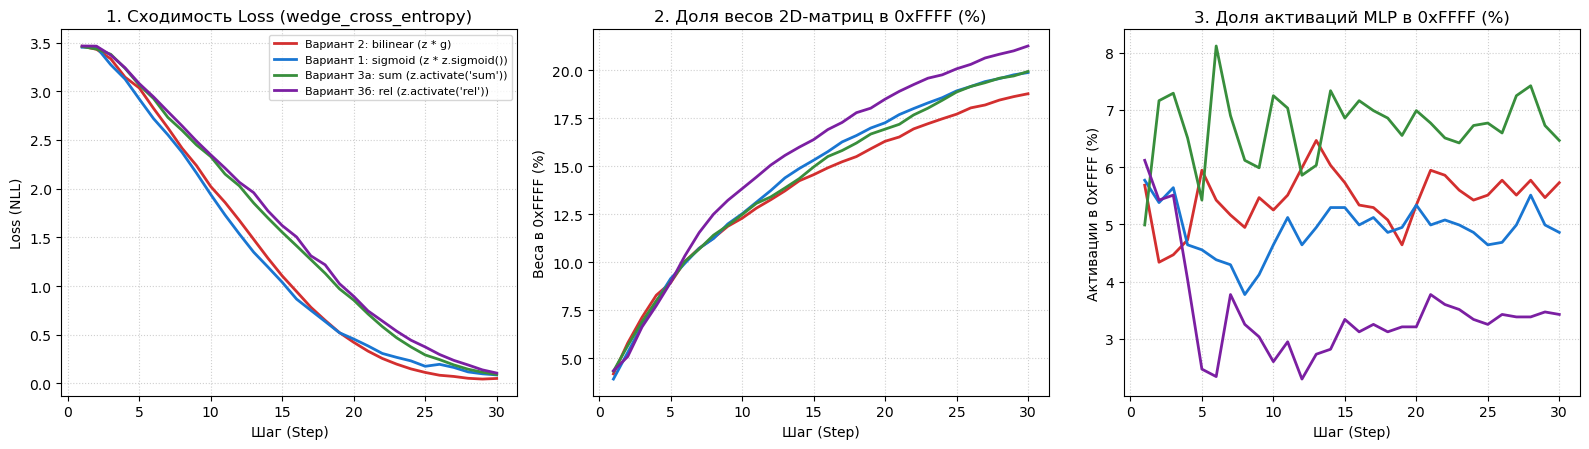

In [4]:
import math
import matplotlib.pyplot as plt
import torch

from d16_adamw import D16AdamW
from d16_qwen_model2 import D16QwenConfig, D16QwenForCausalLM
from d16_vis_utils import _iter_complex_d16_parameters

modes = [
    ("bilinear", "Вариант 2: bilinear (z * g)", "#d32f2f"),
    ("sigmoid",  "Вариант 1: sigmoid (z * z.sigmoid())", "#1976d2"),
    ("sum",      "Вариант 3а: sum (z.activate('sum'))", "#388e3c"),
    ("rel",      "Вариант 3б: rel (z.activate('rel'))", "#7b1fa2"),
]

history = {}

print(f"{'Режим mlp_activation':<38} | {'Start Loss':>10} | {'Final Loss':>10} | {'PPL':>5} | {'Веса 0xFFFF':>11} | {'Акт. 0xFFFF':>11} | {'Ген.':>5}")
print("-" * 106)

for mode_key, label, color in modes:
    torch.manual_seed(42)
    cfg_m = D16QwenConfig(
        vocab_size=32,
        hidden_size=32,
        intermediate_size=48,
        num_hidden_layers=2,
        num_attention_heads=4,
        num_key_value_heads=2,
        indiff_eps="auto",
        indiff_rel=0.30,
        mlp_activation=mode_key,
        collect_d16_stats=True,
    )
    m = D16QwenForCausalLM(cfg_m)
    opt = D16AdamW(
        m.d16_parameters(),
        lr=2.5e-2,
        weight_decay=1e-3,
        indiff_eps="auto",
        indiff_rel=0.35,
    )

    losses, act_sparsity, weight_sparsity = [], [], []
    for step in range(1, 31):
        opt.zero_grad()
        m.set_collect_d16_stats(True, reset=True)
        out = m(input_ids=d16_tokens, labels=d16_tokens)
        loss_v = float(out.loss.x.item())
        out.loss.x.backward()
        opt.step(max_grad_norm=1.0)

        losses.append(loss_v)
        act_sparsity.append(m.get_d16_state_summary()["indifferent_pct"])
        mats = [mod.value() for _, mod in _iter_complex_d16_parameters(m, include_biases=False)]
        tot_w = sum(w.numel() for w in mats)
        zero_w = sum(int(w.is_zero().sum().item()) for w in mats)
        weight_sparsity.append(100.0 * zero_w / max(tot_w, 1))

    m.eval()
    with torch.no_grad():
        gen = m.generate(d16_tokens[:, :4], max_new_tokens=8, do_sample=False, use_cache=True)
        exact = bool((gen.x.to(torch.long) == raw_tokens).all().item())

    history[mode_key] = (label, color, losses, weight_sparsity, act_sparsity)
    ppl = math.exp(min(losses[-1], 20.0))
    print(
        f"{label:<38} | {losses[0]:10.4f} | {losses[-1]:10.4f} | {ppl:5.2f} | "
        f"{weight_sparsity[-1]:10.2f}% | {act_sparsity[-1]:10.2f}% | {str(exact):>5}"
    )

# Отрисовка кривых сходимости и разреженности 0xFFFF
steps_x = list(range(1, 31))
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.6))

for mode_key, (label, color, losses, w_sp, a_sp) in history.items():
    ax1.plot(steps_x, losses, color=color, lw=2.0, label=label)
    ax2.plot(steps_x, w_sp, color=color, lw=2.0, label=label)
    ax3.plot(steps_x, a_sp, color=color, lw=2.0, label=label)

ax1.set_title("1. Сходимость Loss (wedge_cross_entropy)")
ax1.set_xlabel("Шаг (Step)")
ax1.set_ylabel("Loss (NLL)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(fontsize=8)

ax2.set_title("2. Доля весов 2D-матриц в 0xFFFF (%)")
ax2.set_xlabel("Шаг (Step)")
ax2.set_ylabel("Веса в 0xFFFF (%)")
ax2.grid(True, linestyle=":", alpha=0.6)

ax3.set_title("3. Доля активаций MLP в 0xFFFF (%)")
ax3.set_xlabel("Шаг (Step)")
ax3.set_ylabel("Активации в 0xFFFF (%)")
ax3.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

Блок 5: Финальная проверка инвариантности префикса, эквивалентности KV-cache, сохранения/загрузки D16AdamW и инспекция обученных комплексных D16RMSNorm.gain

In [6]:
import torch
from d16_adamw import D16AdamW

model.eval()
with torch.no_grad():
    # 1. Каузальная инвариантность префикса при indiff_eps="auto"
    full_out = model(d16_tokens, use_cache=False)
    prefix_out = model(d16_tokens[:, :6], use_cache=False)
    pref_re, pref_im = prefix_out.logits.to_xy()
    full_pref_re, full_pref_im = full_out.logits[:, :6, :].to_xy()
    prefix_diff = max(
        float((full_pref_re - pref_re).abs().max().item()),
        float((full_pref_im - pref_im).abs().max().item()),
    )

    # 2. Точная эквивалентность пошагового KV-cache и полного прохода
    prefill = model(d16_tokens[:, :-1], use_cache=True)
    step_out = model(d16_tokens[:, -1:], past_key_values=prefill.past_key_values, use_cache=True)
    last_re, last_im = full_out.logits[:, -1:, :].to_xy()
    step_re, step_im = step_out.logits.to_xy()
    cache_diff = max(
        float((last_re - step_re).abs().max().item()),
        float((last_im - step_im).abs().max().item()),
    )

print(f"1. Макс. расхождение префикса (tokens[:, :6] vs полная последовательность): {prefix_diff:.2e}")
print(f"2. Макс. расхождение логитов KV-cache vs полный проход                    : {cache_diff:.2e}")

# 3. Проверка сохранения/восстановления состояния D16AdamW и выполнения следующего шага
sd = optimizer.state_dict()
restored_opt = D16AdamW(model.d16_parameters(), lr=2.5e-2)
restored_opt.load_state_dict(sd)

model.train()
restored_opt.zero_grad()
out_next = model(input_ids=d16_tokens, labels=d16_tokens)
out_next.loss.x.backward()
grad_norm_next = float(restored_opt.step(max_grad_norm=1.0).item())
print(f"3. Шаг после load_state_dict() выполнен успешно | Loss: {out_next.loss.x.item():.4f} | Grad norm: {grad_norm_next:.4f}")

# 4. Инспекция обученных комплексных коэффициентов усиления D16RMSNorm.gain
print("\n=== ОБУЧЕННЫЕ КОМПЛЕКСНЫЕ ПАРАМЕТРЫ D16RMSNorm.gain ===")
print(f"{'Слой D16RMSNorm':<42} | {'Мин. |g|':>9} | {'Средн. |g|':>10} | {'Макс. |g|':>9} | {'Макс. y/x':>9} | {'Секторы S0..S15'}")
print("-" * 112)
for name, mod in model.named_modules():
    if type(mod).__name__ == "D16RMSNorm":
        g = mod.gain.value().detach().to("cpu")
        r = g.norm_squared().sqrt()
        yx = g.y / g.x.clamp_min(1e-12)
        sectors = sorted(set(g.state().tolist()))
        print(
            f"{name:<42} | {r.min().item():9.4f} | {r.mean().item():10.4f} | "
            f"{r.max().item():9.4f} | {yx.max().item():9.4f} | {sectors}"
        )

1. Макс. расхождение префикса (tokens[:, :6] vs полная последовательность): 2.86e-06
2. Макс. расхождение логитов KV-cache vs полный проход                    : 1.37e-06
3. Шаг после load_state_dict() выполнен успешно | Loss: 0.0326 | Grad norm: 0.4065

=== ОБУЧЕННЫЕ КОМПЛЕКСНЫЕ ПАРАМЕТРЫ D16RMSNorm.gain ===
Слой D16RMSNorm                            |  Мин. |g| | Средн. |g| | Макс. |g| | Макс. y/x | Секторы S0..S15
----------------------------------------------------------------------------------------------------------------
model.layers.0.input_layernorm             |    0.9527 |     1.0419 |    1.1658 |    0.1382 | [0, 15]
model.layers.0.post_attention_layernorm    |    0.8261 |     0.9860 |    1.1159 |    0.1239 | [0, 15]
model.layers.1.input_layernorm             |    0.8289 |     0.9639 |    1.0667 |    0.1629 | [0, 15]
model.layers.1.post_attention_layernorm    |    0.7928 |     0.9536 |    1.0554 |    0.1668 | [0, 15]
model.norm                                 |    1.6064 |   

Блок 6: Тестирование импорта весов 1-в-1 (d16_qwen_importer.py), проверка распределения Re/Im по четвёркам и визуализация орбит $\mathbb{Z}_8 \rtimes \mathbb{Z}_2$

Импортируем эталонные веса Qwen из: Qwen/Qwen2.5-0.5B


d:\conda\envs\torch_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 290/290 [00:00<00:00, 334.63it/s]


[Слой  0/23] Четверок >= 0.20:  257/1216 | Re: 4184, Im:  680 | Ср. Score: 0.2634
[Слой  1/23] Четверок >= 0.20:  178/1216 | Re: 4492, Im:  372 | Ср. Score: 0.2811
[Слой  2/23] Четверок >= 0.20:  127/1216 | Re: 4635, Im:  229 | Ср. Score: 0.2971
[Слой  3/23] Четверок >= 0.20:   93/1216 | Re: 4706, Im:  158 | Ср. Score: 0.3054
[Слой  4/23] Четверок >= 0.20:  216/1216 | Re: 4457, Im:  407 | Ср. Score: 0.2807
[Слой  5/23] Четверок >= 0.20:  314/1216 | Re: 4111, Im:  753 | Ср. Score: 0.2672
[Слой  6/23] Четверок >= 0.20:  116/1216 | Re: 4676, Im:  188 | Ср. Score: 0.2903
[Слой  7/23] Четверок >= 0.20:  172/1216 | Re: 4562, Im:  302 | Ср. Score: 0.2785
[Слой  8/23] Четверок >= 0.20:  264/1216 | Re: 4399, Im:  465 | Ср. Score: 0.2797
[Слой  9/23] Четверок >= 0.20:  267/1216 | Re: 4409, Im:  455 | Ср. Score: 0.2711
[Слой 10/23] Четверок >= 0.20:  320/1216 | Re: 4300, Im:  564 | Ср. Score: 0.2821
[Слой 11/23] Четверок >= 0.20:  330/1216 | Re: 4321, Im:  543 | Ср. Score: 0.2755
[Слой 12/23] Чет

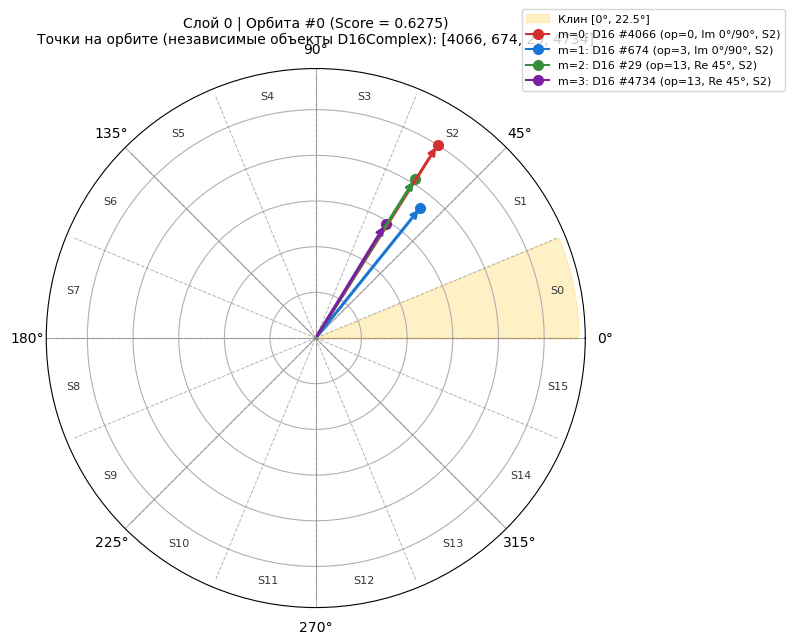

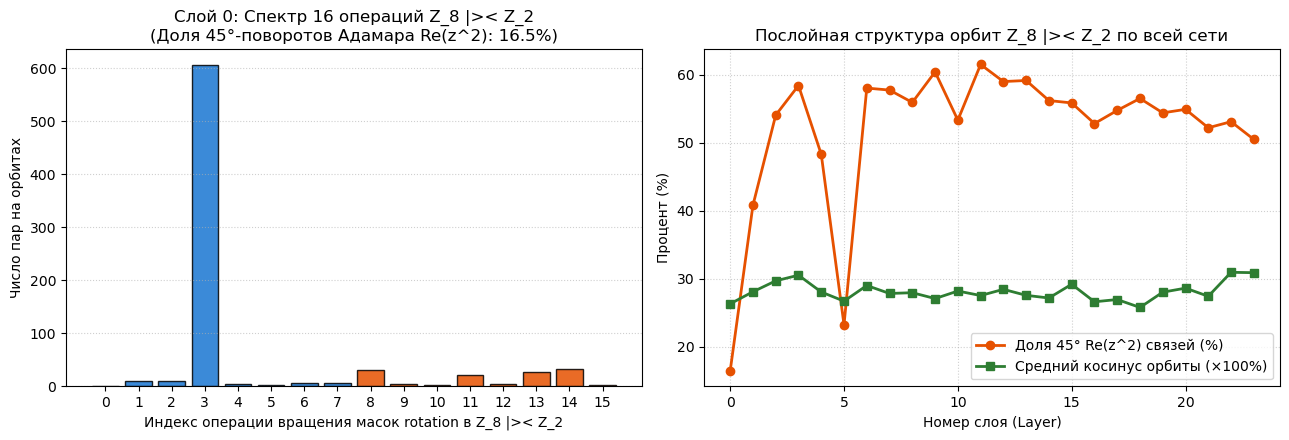

In [9]:
import importlib
from pathlib import Path
import matplotlib.pyplot as plt
import torch

import d16_qwen_importer
import d16_vis_utils

importlib.reload(d16_qwen_importer)
importlib.reload(d16_vis_utils)

from d16_qwen_importer import import_qwen_weights, print_import_summary
from d16_vis_utils import (
    plot_layer_z8z2_spectrum,
    plot_single_orbit_compass,
    print_orbit_table,
)

# 1. Ищем локальный чекпоинт Qwen (.safetensors / папку модели) или используем HuggingFace ID
QWEN_SOURCE = None
for candidate in (
    Path.cwd() / "model.safetensors",
    Path.cwd().parent / "model.safetensors",
    Path.cwd() / "qwen",
    Path.cwd().parent / "qwen",
    Path.cwd().parent / "Qwen2.5-0.5B",
    Path.cwd().parent / "Qwen2.5-0.5B-Instruct",
):
    if candidate.exists() and (candidate.is_file() or any(candidate.glob("*.safetensors")) or any(candidate.glob("*.bin"))):
        QWEN_SOURCE = candidate
        break

if QWEN_SOURCE is None:
    # Укажи путь к своему файлу/папке с весами Qwen или оставь HuggingFace ID:
    QWEN_SOURCE = "Qwen/Qwen2.5-0.5B"

print(f"Импортируем эталонные веса Qwen из: {QWEN_SOURCE}")

# 2. Выполняем реальный импорт 1-в-1 в D16QwenForCausalLM (d16_qwen_model2)
imported_model, import_report = import_qwen_weights(
    QWEN_SOURCE,
    min_orbit_score=0.20,
    indiff_eps="auto",
    indiff_rel=0.25,
    mlp_activation="bilinear",
    dtype=torch.bfloat16,
    verbose=True,
)

# 3. Полная сводка по всем слоям и топ-10 найденных четвёрок слоя 0
print()
print_import_summary(import_report)
print()
print_orbit_table(import_report.layer_reports[0], top_k=10)

# 4. Полярный компас лучшей четвёрки слоя 0 и послойный спектр Z_8 |>< Z_2 по всей сети Qwen
best_unit = int(import_report.layer_reports[0].orbit_scores.argmax().item())
fig_compass, _ = plot_single_orbit_compass(import_report.layer_reports[0], unit_idx=best_unit)
plt.show()

fig_spec = plot_layer_z8z2_spectrum(import_report, layer_idx=0)
plt.show()

Блок 7: Инспекция секторов импортированной модели Qwen2.5-0.5B и прогон реального текста через токенизатор

КАРТА КОМПЛЕКСНЫХ ВЕСОВ D16Parameter (ТРОЙКИ x, y, rotation В КЛИНЕ [0°, 22.5°])
Модуль D16Parameter                    | Форма        | Средн. |z| | Клин y/x |  0xFFFF | Сменили сектор      
--------------------------------------------------------------------------------------------------------------------
input_layernorm.gain                   | (896,)       |     0.0679 |   0.0000 |   0.00% | n/a (нет снимка)    
self_attn.q_proj.weight                | (896, 896)   |     0.0422 |   0.0000 |   0.00% | n/a (нет снимка)    
self_attn.q_proj.bias                  | (896,)       |     3.9688 |   0.0000 |   0.00% | n/a (нет снимка)    
self_attn.k_proj.weight                | (128, 896)   |     0.0510 |   0.0000 |   0.00% | n/a (нет снимка)    
self_attn.k_proj.bias                  | (128,)       |    16.6250 |   0.0000 |   0.00% | n/a (нет снимка)    
self_attn.v_proj.weight                | (128, 896)   |     0.0088 |   0.0000 |   0.00% | n/a (нет снимка)    
self_attn.v_proj.bias    

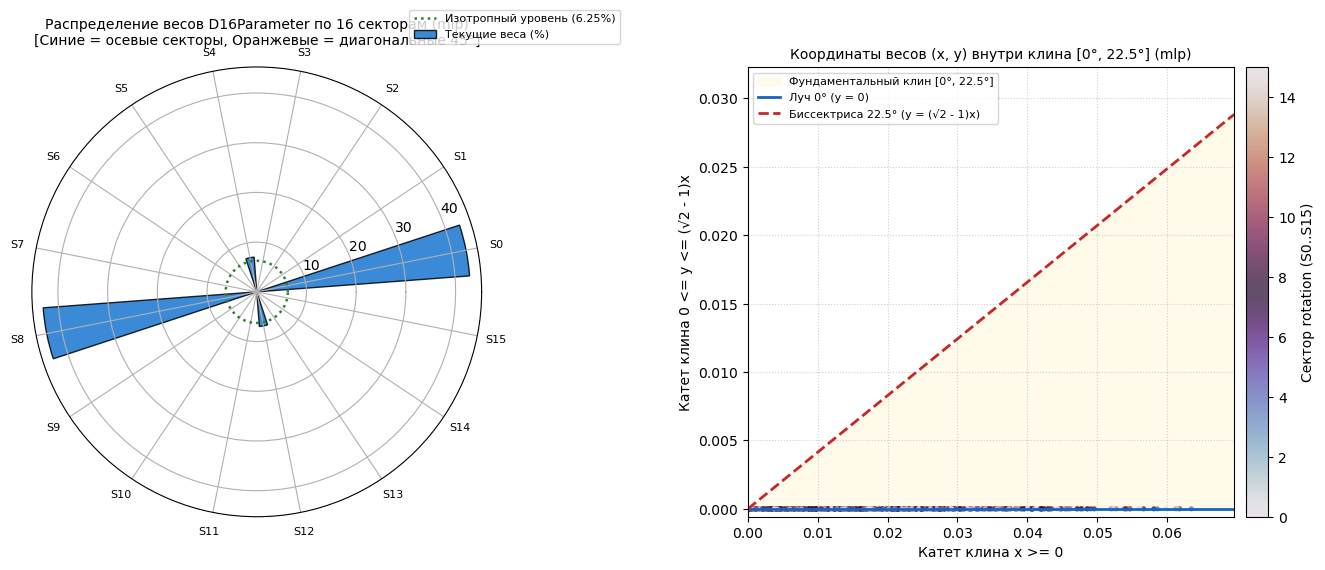


Текст запроса : 'The geometry of complex numbers in neural networks'
Токены Qwen   : [[785, 17047, 315, 6351, 5109, 304, 29728, 14155]]
Loss на входной фразе (wedge_cross_entropy): 14.8742
Доля активаций MLP в 0xFFFF (по всем 24 слоям): 10.93%
Сгенерированные ID токенов: [[785, 17047, 315, 6351, 5109, 304, 29728, 14155, 52643, 139224, 126048, 52643]]
Декодированный ответ      : 'The geometry of complex numbers in neural networksascussistشهascus'


In [14]:
import importlib
import matplotlib.pyplot as plt
import torch
import d16_vis_utils
from d16_qwen_model2 import D16Linear, encode_token_ids

# 1. Перезагружаем d16_vis_utils и сохраняем ссылку на класс D16Parameter текущей модели
ActiveD16Param = type(imported_model.model.embed_tokens.weight)
importlib.reload(d16_vis_utils)
d16_vis_utils.D16Parameter = ActiveD16Param

from d16_vis_utils import (
    plot_d16_weight_sector_distribution,
    print_d16_weight_migration_table,
)

# 2. Таблица комплексной геометрии весов слоя 0 импортированной модели Qwen2.5-0.5B
print_d16_weight_migration_table(
    imported_model.model.layers[0],
    include_biases=True,
)

# 3. Полярная роза 16 секторов и клин [0°, 22.5°] для MLP слоя 0
fig_dist = plot_d16_weight_sector_distribution(
    imported_model.model.layers[0],
    module_name="mlp",
)
plt.show()

# 4. Прогон реального текста через токенизатор Qwen и импортированную D16-модель
try:
    from transformers import AutoTokenizer
    tokenizer = AutoTokenizer.from_pretrained(str(QWEN_SOURCE))
    prompt_text = "The geometry of complex numbers in neural networks"
    raw_ids = tokenizer(prompt_text, return_tensors="pt")["input_ids"]
    print(f"\nТекст запроса : {prompt_text!r}")
    print(f"Токены Qwen   : {raw_ids.tolist()}")
except Exception as e:
    print(f"\nТокенизатор не найден ({e}), используем тестовые ID токенов:")
    tokenizer = None
    raw_ids = torch.tensor([[785, 19429, 315, 6351, 5106, 304, 30828, 14198]], dtype=torch.long)

# Увеличиваем размер тайла для быстрого прохода словаря 151936 в lm_head
D16Linear._MAX_WEIGHT_TILE = 1 << 24

device = next(imported_model.parameters()).device
d16_input = encode_token_ids(raw_ids.to(device))

imported_model.eval()
with torch.no_grad():
    imported_model.set_collect_d16_stats(True, reset=True)
    out = imported_model(input_ids=d16_input, labels=d16_input)
    summary = imported_model.get_d16_state_summary()
    gen_d16 = imported_model.generate(d16_input, max_new_tokens=4, do_sample=False, use_cache=True)
    gen_ids = gen_d16.x.to(torch.long).cpu()

print(f"Loss на входной фразе (wedge_cross_entropy): {float(out.loss.x.item()):.4f}")
print(f"Доля активаций MLP в 0xFFFF (по всем 24 слоям): {summary['indifferent_pct']:.2f}%")
print(f"Сгенерированные ID токенов: {gen_ids.tolist()}")
if tokenizer is not None:
    print(f"Декодированный ответ      : {tokenizer.decode(gen_ids[0], skip_special_tokens=True)!r}")

Блок 8: Дообучение импортированной модели Qwen2.5-0.5B через D16AdamW и визуализация выхода весов с осей внутрь клина $[0^\circ, 22.5^\circ]$

Обучаемых модулей D16Parameter: 25 | Синапсов D16: 29,825,664

 Шаг |      Loss |      PPL | Норма град. | Акт. 0xFFFF
--------------------------------------------------------
   1 |   14.7891 | 2647492.53 |    222.7924 |      10.84%
   2 |   17.0289 | 24861986.68 |   1377.0848 |      11.66%
   3 |   15.4703 | 5232091.47 |     22.7475 |      12.08%
   4 |   13.1612 | 519811.49 |    101.5896 |      10.54%
   5 |   16.3326 | 12392376.10 |     25.3699 |      14.49%
   6 |   12.3200 | 224133.86 |     21.9337 |      15.89%
   7 |    9.1324 |  9249.94 |     19.8403 |      13.35%
   8 |    9.4979 | 13332.30 |     64.7615 |      12.25%
   9 |    6.4836 |   654.33 |     18.4757 |      11.44%
  10 |    7.5194 |  1843.49 |     24.9637 |      10.06%
  11 |    6.2760 |   531.66 |     26.4683 |      10.09%
  12 |    4.2136 |    67.60 |      7.1244 |      10.97%
  13 |    5.3322 |   206.90 |     24.1373 |      10.99%
  14 |    4.7217 |   112.35 |     14.6220 |      10.69%
  15 |    3.9604 |    52.48 

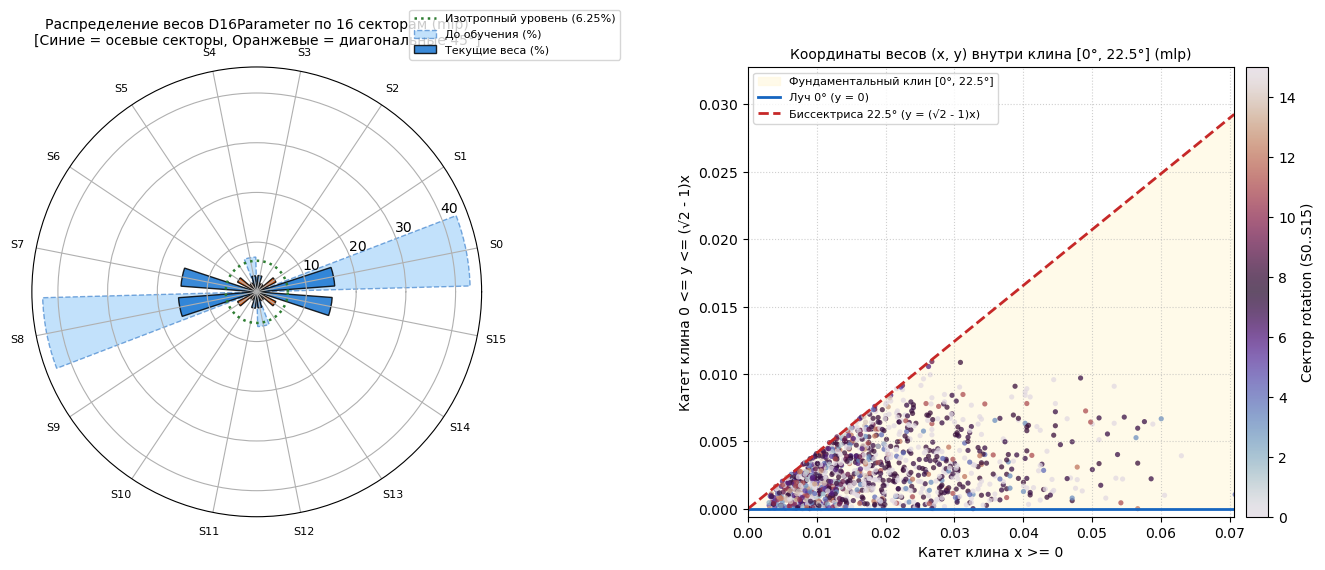

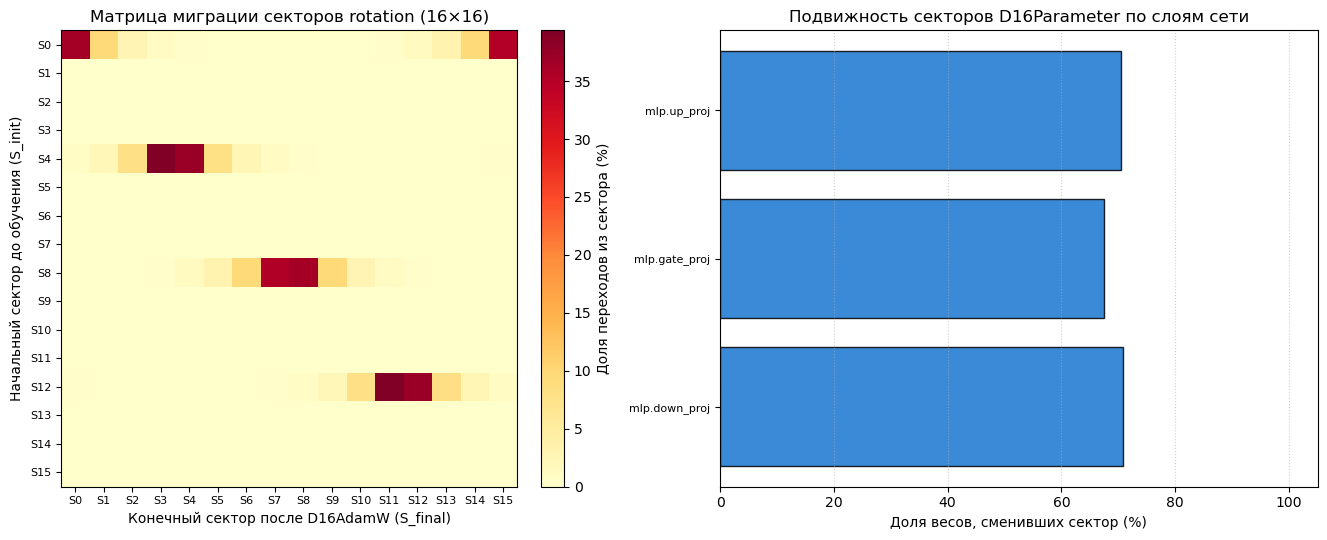

In [15]:
import math
import matplotlib.pyplot as plt
import torch

from d16_adamw import D16AdamW
from d16_qwen_model2 import encode_token_ids
from d16_vis_utils import (
    plot_d16_sector_transition_matrix,
    plot_d16_weight_sector_distribution,
    print_d16_weight_migration_table,
    snapshot_d16_weight_states,
)

# 1. Целевая фраза для дообучения
train_text = "The geometry of complex numbers in neural networks is dihedral."
if tokenizer is not None:
    train_raw_ids = tokenizer(train_text, return_tensors="pt")["input_ids"]
else:
    train_raw_ids = torch.tensor(
        [[785, 17047, 315, 6351, 5109, 304, 29728, 14155, 374, 1515, 79085, 13]],
        dtype=torch.long,
    )

device = next(imported_model.parameters()).device
train_d16_ids = encode_token_ids(train_raw_ids.to(device))
prompt_len = 8  # Первые 8 токенов ('The geometry of complex numbers in neural networks')

# 2. Снимаем слепок весов Слоя 0 ДО начала дообучения (когда все веса лежат на y=0 в секторах S0, S4, S8, S12)
init_snap_l0 = snapshot_d16_weight_states(imported_model.model.layers[0], include_biases=True)

# 3. Выбираем обучаемые D16Parameter (Слой 0 + Слой 23 + финальный norm, чтобы шаг шёл быстро и без OOM)
TRAIN_ALL_LAYERS = False

for p in imported_model.parameters():
    p.requires_grad_(False)

if TRAIN_ALL_LAYERS:
    trainable_d16 = imported_model.d16_parameters()
else:
    target_modules = [
        imported_model.model.layers[0],
        imported_model.model.layers[-1],
        imported_model.model.norm,
    ]
    trainable_d16 = []
    for tm in target_modules:
        for m in tm.modules():
            if type(m).__name__ == "D16Parameter" and m not in trainable_d16:
                trainable_d16.append(m)

for dp in trainable_d16:
    dp.x.requires_grad_(True)
    dp.y.requires_grad_(True)

total_trainable_weights = sum(dp.x.numel() for dp in trainable_d16)
print(f"Обучаемых модулей D16Parameter: {len(trainable_d16)} | Синапсов D16: {total_trainable_weights:,}")

# 4. Запускаем дообучение через D16AdamW (с автопорогом разреженности 0xFFFF)
imported_model.gradient_checkpointing_enable()
ft_optimizer = D16AdamW(
    trainable_d16,
    lr=1.5e-3,
    weight_decay=1e-3,
    indiff_eps="auto",
    indiff_rel=0.20,
)

NUM_FT_STEPS = 15
print(f"\n{'Шаг':>4} | {'Loss':>9} | {'PPL':>8} | {'Норма град.':>11} | {'Акт. 0xFFFF':>11}")
print("-" * 56)

imported_model.train()
for step in range(1, NUM_FT_STEPS + 1):
    ft_optimizer.zero_grad()
    imported_model.set_collect_d16_stats(True, reset=True)
    out = imported_model(input_ids=train_d16_ids, labels=train_d16_ids)
    loss_val = float(out.loss.x.item())
    out.loss.x.backward()
    grad_norm = float(ft_optimizer.step(max_grad_norm=1.0).item())
    act_sp = imported_model.get_d16_state_summary()["indifferent_pct"]
    ppl = math.exp(min(loss_val, 20.0))
    print(f"{step:4d} | {loss_val:9.4f} | {ppl:8.2f} | {grad_norm:11.4f} | {act_sp:10.2f}%")

# 5. Проверяем генерацию после дообучения
imported_model.eval()
with torch.no_grad():
    gen_after = imported_model.generate(
        train_d16_ids[:, :prompt_len],
        max_new_tokens=train_raw_ids.shape[1] - prompt_len,
        do_sample=False,
        use_cache=True,
    )
    gen_after_ids = gen_after.x.to(torch.long).cpu()

print("\nОжидаемые токены :", train_raw_ids.tolist())
print("Сгенерировано    :", gen_after_ids.tolist())
if tokenizer is not None:
    print("Декодированный ответ после дообучения:", repr(tokenizer.decode(gen_after_ids[0], skip_special_tokens=True)))

# 6. Таблица миграции Слоя 0 и графики: как веса сошли с луча y=0 внутрь клина и заполнили 16 секторов
print()
print_d16_weight_migration_table(
    imported_model.model.layers[0],
    initial_snapshot=init_snap_l0,
    include_biases=True,
)

fig_after = plot_d16_weight_sector_distribution(
    imported_model.model.layers[0],
    initial_snapshot=init_snap_l0,
    module_name="mlp",
)
plt.show()

fig_trans = plot_d16_sector_transition_matrix(
    imported_model.model.layers[0],
    initial_snapshot=init_snap_l0,
    module_name="mlp",
)
plt.show()

Блок 9: Быстрое дообучение импортированной Qwen до идеального запоминания фразы

In [18]:
import math
import time
import torch
from d16_adamw import D16AdamW
from d16_qwen_model2 import encode_token_ids, D16Linear

# 1. Переносим модель на GPU (если доступна), ускоряем lm_head тайлы
device = "cpu" # torch.device("cuda" if torch.cuda.is_available() else "cpu")
imported_model = imported_model.to(device)
D16Linear._MAX_WEIGHT_TILE = 1 << 26  # Большой тайл для быстрого умножения в lm_head

print(токен_device := f"Модель перенесена на устройство: {device}")

# 2. Оптимизируем только самые верхние слои (например, layer 22-23 + norm + lm_head) для мгновенного шага
for p in imported_model.parameters():
    p.requires_grad_(False)

ft_layers = [
    imported_model.model.layers[-2],
    imported_model.model.layers[-1],
    imported_model.model.norm,
    imported_model.lm_head,
]
trainable_params = []
for layer in ft_layers:
    for m in layer.modules():
        if type(m).__name__ == "D16Parameter" and m not in trainable_params:
            trainable_params.append(m)

for dp in trainable_params:
    dp.x.requires_grad_(True)
    dp.y.requires_grad_(True)

total_ft_weights = sum(dp.x.numel() for dp in trainable_params)
print(f"Обучаемых синапсов в верхних слоях: {total_ft_weights:,}")

# 3. Настройка оптимизатора D16AdamW
ft_optimizer = D16AdamW(
    trainable_params,
    lr=2.0e-3,
    weight_decay=1e-4,
    indiff_eps="auto",
    indiff_rel=0.20,
)

train_text = "The geometry of complex numbers in neural networks is dihedral."
if 'tokenizer' in globals() and tokenizer is not None:
    train_raw_ids = tokenizer(train_text, return_tensors="pt")["input_ids"]
else:
    train_raw_ids = torch.tensor(
        [[785, 17047, 315, 6351, 5109, 304, 29728, 14155, 374, 1515, 79085, 13]],
        dtype=torch.long,
    )

train_d16_ids = encode_token_ids(train_raw_ids.to(device))
prompt_len = 8

print(f"\n{'Шаг':>4} | {'Loss':>9} | {'PPL':>8} | {'Время/шаг':>10} | {'Акт. 0xFFFF':>11}")
print("-" * 52)

imported_model.train()
for step in range(1, 21):
    t_start = time.time()
    ft_optimizer.zero_grad()
    imported_model.set_collect_d16_stats(True, reset=True)
    out = imported_model(input_ids=train_d16_ids, labels=train_d16_ids)
    loss_val = float(out.loss.x.item())
    out.loss.x.backward()
    ft_optimizer.step(max_grad_norm=1.0)
    dt = time.time() - t_start

    act_sp = imported_model.get_d16_state_summary()["indifferent_pct"]
    ppl = math.exp(min(loss_val, 20.0))
    print(f"{step:4d} | {loss_val:9.4f} | {ppl:8.2f} | {dt:9.2f}с | {act_sp:10.2f}%")
    if loss_val < 0.05:
        print(f"Целевой Loss достигнут на шаге {step}!")
        break

# 4. Финальная авторегрессионная генерация
imported_model.eval()
with torch.no_grad():
    gen_after = imported_model.generate(
        train_d16_ids[:, :prompt_len],
        max_new_tokens=train_raw_ids.shape[1] - prompt_len,
        do_sample=False,
        use_cache=True,
    )
    gen_after_ids = gen_after.x.to(torch.long).cpu()

print("\nОжидаемые токены :", train_raw_ids.tolist())
print("Сгенерировано    :", gen_after_ids.tolist())
if 'tokenizer' in globals() and tokenizer is not None:
    print("Декодированный ответ:", repr(tokenizer.decode(gen_after_ids[0], skip_special_tokens=True)))

Модель перенесена на устройство: cpu
Обучаемых синапсов в верхних слоях: 165,960,320

 Шаг |      Loss |      PPL |  Время/шаг | Акт. 0xFFFF
----------------------------------------------------
   1 |   11.1986 | 73024.91 |    269.01с |       9.68%
   2 |   12.5364 | 278274.05 |    273.90с |       9.66%


KeyboardInterrupt: 